# Análisis O<sup>3</sup> horario de UIZ

## Datos y librerias

In [16]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss
sns.set_theme(style="whitegrid")

In [6]:
df = pd.read_csv(
    "contaminantes/contaminantes_2026_nuevo.csv", skiprows=9)
df = df.loc[(df["id_station"] == "UIZ") & (df["id_parameter"] == "O3")].copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["valor"] = pd.to_numeric(df["valor"], errors="coerce")
df = df.dropna(subset=["date"]).sort_values("date")
print("Filas UIZ/O3:", len(df))
print("Intervalo:", df["date"].min(), "a", df["date"].max())
display(df.head())

Filas UIZ/O3: 5088
Intervalo: 2026-01-01 00:00:00 a 2026-07-31 23:00:00


,date,id_station,id_parameter,valor,unit
283,2026-01-01 00:00:00,UIZ,O3,14.0,1
589,2026-01-01 01:00:00,UIZ,O3,5.0,1
895,2026-01-01 02:00:00,UIZ,O3,2.0,1
1201,2026-01-01 03:00:00,UIZ,O3,3.0,1
1507,2026-01-01 04:00:00,UIZ,O3,3.0,1


Filtramos unicamente lo correspondiente a la estación UIZ y a O3. También convertimos los valores númericos y fechas, eliminamos fechas inválidas y ordenamos los datos cronologicamente.

## a) Cuente los huecos y decida como tratarlos

In [18]:
duplicados = int(df["date"].duplicated().sum())
if duplicados:
    print(f"Aviso: {duplicados} fechas duplicadas; se promedian sus mediciones.")
observada = df.groupby("date")["valor"].mean().sort_index()
indice = pd.date_range(observada.index.min(), observada.index.max(), freq="h")
serie = observada.reindex(indice).rename("O3")
serie.index.name = "date"
horas_no_registradas = len(indice.difference(observada.index))
nan_originales = int(observada.isna().sum())

es_na = serie.isna()
grupo_hueco = es_na.ne(es_na.shift()).cumsum()
longitudes = es_na.groupby(grupo_hueco).transform("sum")

serie_tratada = serie.interpolate(method="time", limit_area="inside")
serie_tratada[es_na & (longitudes > 3)] = np.nan
imputados = int((serie.isna() & serie_tratada.notna()).sum())

resumen_huecos = pd.DataFrame({"Métrica": ["Horas del periodo", "Horas sin registro", "Lecturas NaN originales", "Huecos totales", "Horas interpoladas", "Huecos restantes", "Fechas duplicadas"],
"Valor": [len(serie), horas_no_registradas, nan_originales, int(es_na.sum()), imputados, int(serie_tratada.isna().sum()), duplicados]})
display(resumen_huecos)

,Métrica,Valor
0,Horas del periodo,5088
1,Horas sin registro,0
2,Lecturas NaN originales,228
3,Huecos totales,228
4,Horas interpoladas,124
5,Huecos restantes,104
6,Fechas duplicadas,0


Identificamos fechas y horas duplicadas, calculamos el promedio y reconstruimos. Identificamos los valores faltantes consecutivos y medimos la longitud de los tramos. Usamos interpolación temporal para estimar los valores faltantes cuando los huecos son de 3 horas consecutivas.

Los registros horarios están completos en términos de fechas, pero 228 mediciones no tienen valor. Podemos recuperar 124 mediante interpolación, dejando 104 sin modificar.

## b) Grafique la serie y su ACF hasta 72 horas

C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


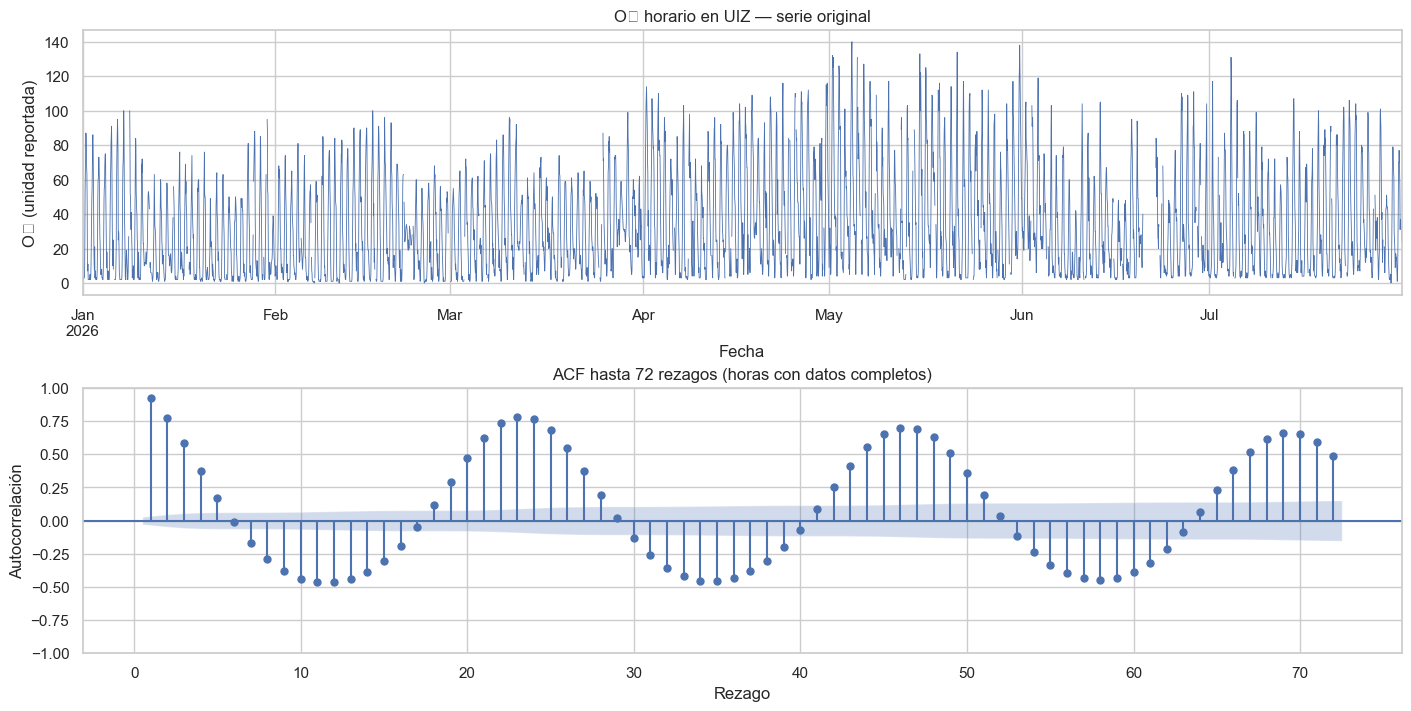

In [19]:
def grafica_serie_acf(s, titulo, lags=72):
    fig, ax = plt.subplots(2, 1, figsize=(14, 7), constrained_layout=True)
    s.plot(ax=ax[0], linewidth=0.6)
    ax[0].set(title=titulo, xlabel="Fecha", ylabel="O₃ (unidad reportada)")
    s_ok = s.dropna()
    if len(s_ok) > lags + 1:
        plot_acf(s_ok, lags=lags, ax=ax[1], zero=False, alpha=0.05)
    ax[1].set(title=f"ACF hasta {lags} rezagos (horas con datos completos)", xlabel="Rezago", ylabel="Autocorrelación")
    plt.show()

grafica_serie_acf(serie, "O₃ horario en UIZ — serie original")

La primera gráfica muestra como cambia la concentración de ozono durante el periodo. La segunda gráfica muestra que tan relacionada está una observación con otras observaciones anteriores.

## c) Corra ADF y KPSS

In [22]:
def segmento_continuo_mas_largo(s):
    valido = s.notna()
    ids = valido.ne(valido.shift()).cumsum()
    segmentos = [trozo for _, trozo in s.groupby(ids) if trozo.notna().all()]
    return max(segmentos, key=len) if segmentos else s.iloc[:0]

def pruebas_estacionariedad(s, nombre):
    limpia = segmento_continuo_mas_largo(s)
    if len(limpia) < 100 or limpia.nunique() < 2:
        return {"Serie": nombre, "N segmento": len(limpia), "ADF p": np.nan, "KPSS p": np.nan, "Conclusión": "Datos insuficientes"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        adf_p = adfuller(limpia, autolag="AIC")[1]
        kpss_p = kpss(limpia, regression="c", nlags="auto")[1]
    if adf_p < 0.05 and kpss_p >= 0.05:
        conclusion = "Compatible con estacionariedad"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        conclusion = "Evidencia de no estacionariedad"
    else:
        conclusion = "Resultados mixtos"
    return {"Serie": nombre, "N segmento": len(limpia), "ADF p": adf_p, "KPSS p": kpss_p, "Conclusión": conclusion}

resultado_original = pruebas_estacionariedad(serie_tratada, "Original (huecos cortos tratados)")
display(pd.DataFrame([resultado_original]))

,Serie,N segmento,ADF p,KPSS p,Conclusión
0,Original (huecos cortos tratados),1135,0.054754,0.01,Evidencia de no estacionariedad


Como 0.0548 es mayor que 0.05, ADF no rechaza la hipótesis de raíz unitaria. En cambio, KPSS rechaza la estacionariedad porque su p-value es 0.01.
Esto sugiere que la serie original necesita alguna transformación para reducir sus patrones sistemáticos.

## d) Reste la media de cada hora del día y repita c)

,Serie,N segmento,ADF p,KPSS p,Conclusión
0,Original (huecos cortos tratados),1135,0.054754,0.01,Evidencia de no estacionariedad
1,Centrada por hora,1135,0.007849,0.01,Resultados mixtos


C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


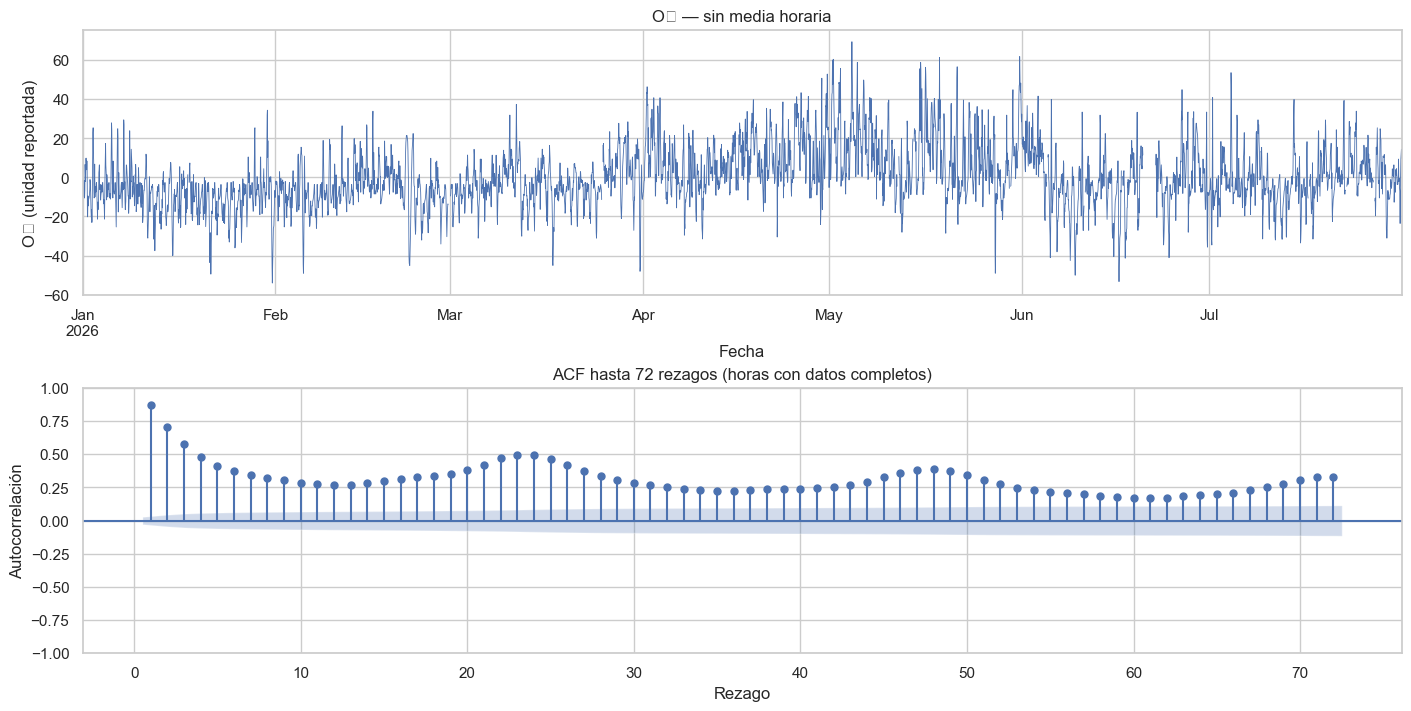

In [23]:
medias_hora = serie_tratada.groupby(serie_tratada.index.hour).transform("mean")
serie_hora = (serie_tratada - medias_hora).rename("O3_sin_patron_horario")
display(pd.DataFrame([resultado_original, pruebas_estacionariedad(serie_hora, "Centrada por hora")]))
grafica_serie_acf(serie_hora, "O₃ — sin media horaria")

## e) Reste la media de cada hora del día y repita c)

,Serie,N segmento,ADF p,KPSS p,Conclusión
0,Original (huecos cortos tratados),1135,5.475397e-02,0.010000,Evidencia de no estacionariedad
1,Centrada por hora,1135,7.848921e-03,0.010000,Resultados mixtos
2,Centrada por mes × hora,1135,1.016177e-18,0.053552,Compatible con estacionariedad


C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


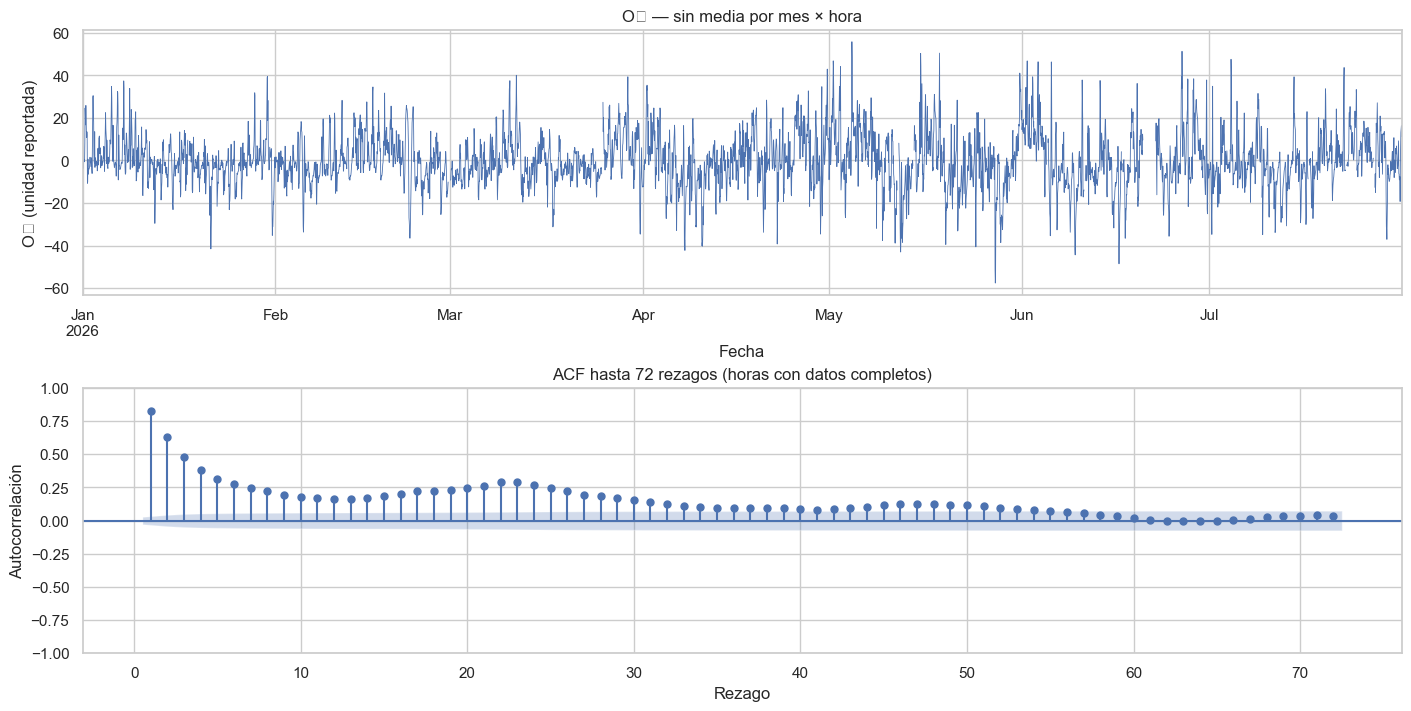

In [24]:
mes_hora = [serie_tratada.index.month, serie_tratada.index.hour]
medias_mes_hora = serie_tratada.groupby(mes_hora).transform("mean")
serie_mes_hora = (serie_tratada - medias_mes_hora).rename("O3_sin_patron_mes_hora")
resultados_base = [resultado_original, pruebas_estacionariedad(serie_hora, "Centrada por hora"), pruebas_estacionariedad(serie_mes_hora, "Centrada por mes × hora")]
display(pd.DataFrame(resultados_base))
grafica_serie_acf(serie_mes_hora, "O₃ — sin media por mes × hora")

## f) Haga la diferencia de 24 horas, repita c) y compare su ACF y su varianza con las de e)

,Serie,N segmento,ADF p,KPSS p,Conclusión
0,Original (huecos cortos tratados),1135,5.475397e-02,0.010000,Evidencia de no estacionariedad
1,Centrada por hora,1135,7.848921e-03,0.010000,Resultados mixtos
2,Centrada por mes × hora,1135,1.016177e-18,0.053552,Compatible con estacionariedad
3,Diferencia de 24 h,1111,9.596447e-16,0.100000,Compatible con estacionariedad


C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\erida\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


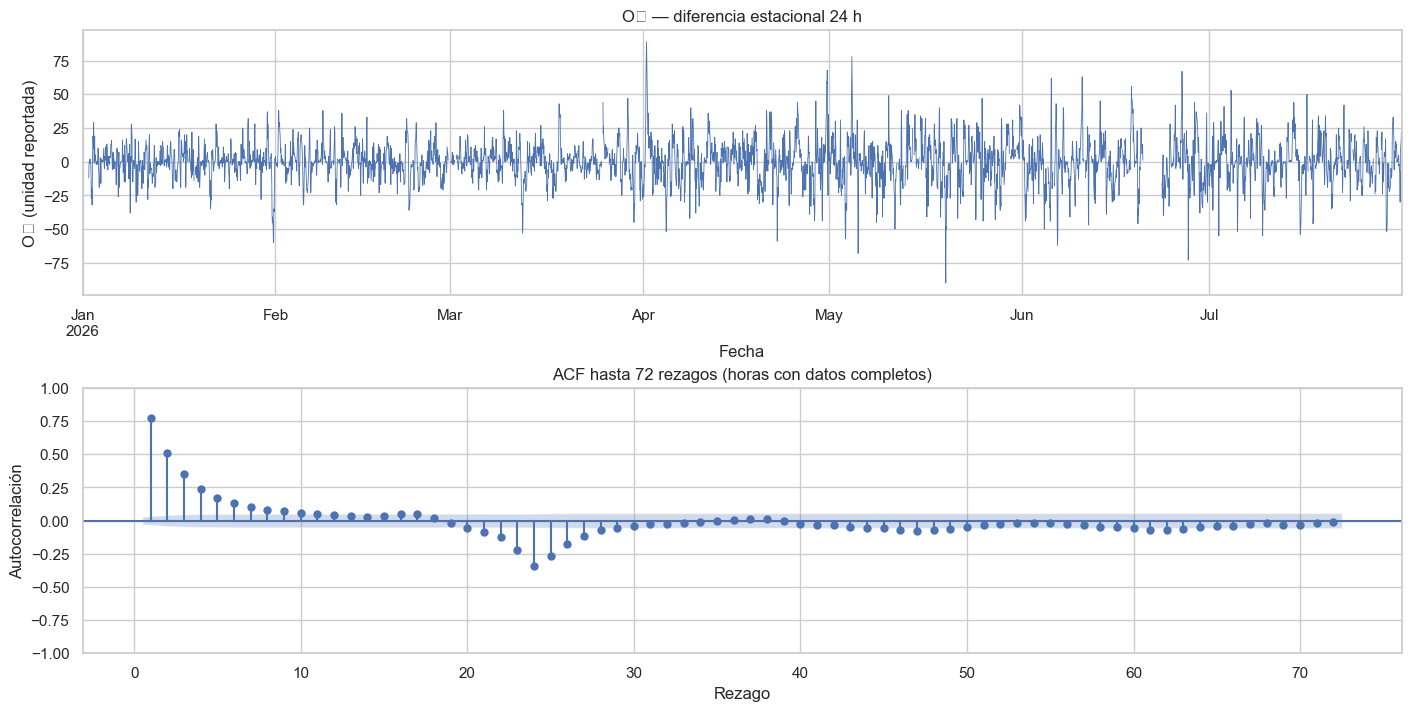

Fechas comunes para comparar varianzas: 4881


,Método,Varianza (todos los datos válidos),Varianza (fechas comunes)
0,Centrado por mes × hora,156.319462,157.048158
1,Diferencia de 24 h,233.192310,233.192310


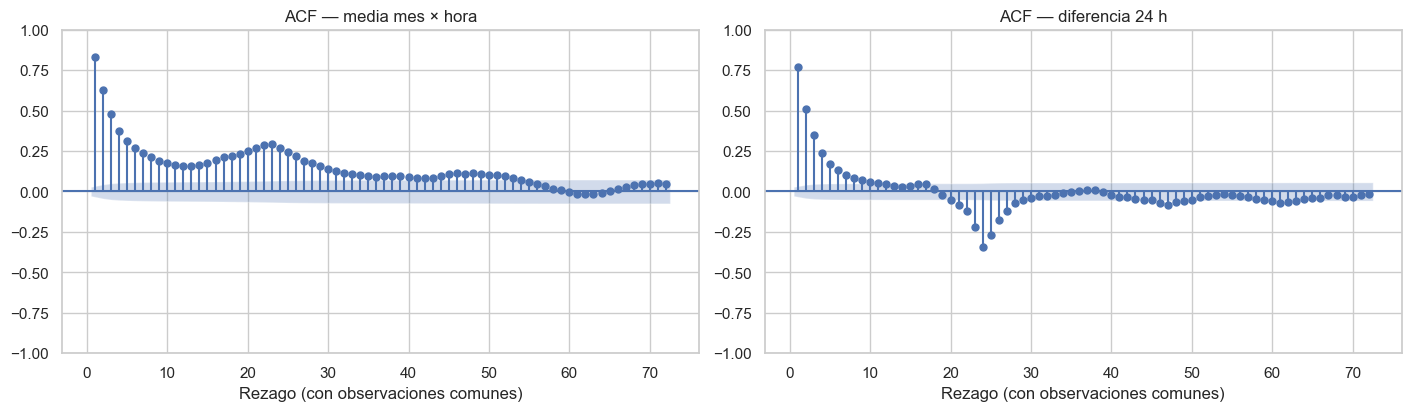

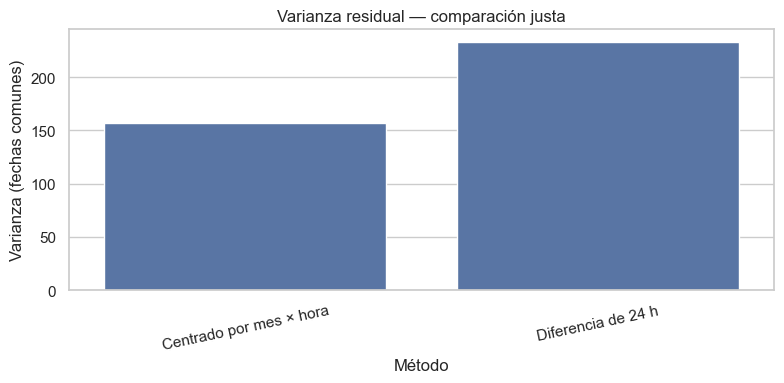

In [27]:
serie_diff24 = serie_tratada.diff(24).rename("O3_diferencia_24h")
resultados = pd.DataFrame(resultados_base + [pruebas_estacionariedad(serie_diff24, "Diferencia de 24 h")])
display(resultados)
grafica_serie_acf(serie_diff24, "O₃ — diferencia estacional 24 h")

comparables = pd.concat({"Mes × hora": serie_mes_hora, "Diferencia 24 h": serie_diff24}, axis=1).dropna()
varianzas = pd.DataFrame({
    "Método": ["Centrado por mes × hora", "Diferencia de 24 h"],
    "Varianza (todos los datos válidos)": [serie_mes_hora.var(ddof=1), serie_diff24.var(ddof=1)],
    "Varianza (fechas comunes)": [comparables["Mes × hora"].var(ddof=1), comparables["Diferencia 24 h"].var(ddof=1)]
})
print("Fechas comunes para comparar varianzas:", len(comparables))
display(varianzas)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

plot_acf(comparables["Mes × hora"], lags=72, zero=False, ax=ax[0])
plot_acf(comparables["Diferencia 24 h"], lags=72, zero=False, ax=ax[1])
ax[0].set_title("ACF — media mes × hora")
ax[1].set_title("ACF — diferencia 24 h")
for eje in ax:
    eje.set_xlabel("Rezago (con observaciones comunes)")
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=varianzas, x="Método", y="Varianza (fechas comunes)")
plt.xticks(rotation=12)
plt.title("Varianza residual — comparación justa")
plt.tight_layout()
plt.show()